In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

# Exoplanet Archive aggregate (not used here since the bias maps moved to Bias_Maps.ipynb)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from target data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# K2-141b Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
# Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
# 0.3 seems like a reasonable assumption for TOI-2431b
A_B = 0.3 #3/2 * Ag # 0.42
# More physical would be:
# A_B = 0.1 # typical lava world in optical (Essack 2020), probably slight underestimate for bolometric.
# A_B = q * f_red * Ag_opt # with q~0.6 (more realistic for e.g. moon, Mercury), and f_red a spectral correction factor.

# ASSUMPTION (!)
# Model for band-integrated albedo in the observing band (MIR)
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.

In [4]:
# Filter to be used
instrument = "MIRI/LRS" # "JWST_NIRSpec.G395H_NRS1"  # "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

## Detectability and parameter bias analysis

The detection error per minute comes from PandExo for the planet and instrument set above (printed below). For comparison, K2-141 b has 154.5 ppm per minute (PandExo, MIRI/LRS 5.0–10.5 µm).


In [5]:
n_bins = 27 # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes]
sigma_1min = rms_1min(planet, instrument)
n_orbits        = 5 # number of orbits observed (3 orbits has been done)


l1, l2 = lrs_range

A_B_true = A_B  # 3/2 * Ag(Zieba2022) = 0.42;  under A = A_B this single albedo sets BOTH the reflected amplitude and the Bond albedo (dayside temperature)

# context for the bias-analysis functions imported from simple_bias_analysis.py (bounds=(0.0, 0.6) by default)
cfg = FittingConfig(planet=planet, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_B=u_B, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

PandExo inputs for TOI-2431 b  [instrument=MIRI/LRS (PandExo: MIRI LRS)]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.534        R_earth          <- pl_rade
    rs_rsun    = 0.651        R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.7475       h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Group Numbe

### 1. Pure Detectability

In [6]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t_k, pc_k, fp_k = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B)
t_n, pc_n, fp_n = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive", u_B=u_B)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, lc_k, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B, include_transit=False)
_, lc_n, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive",      u_B=u_B, include_transit=False)

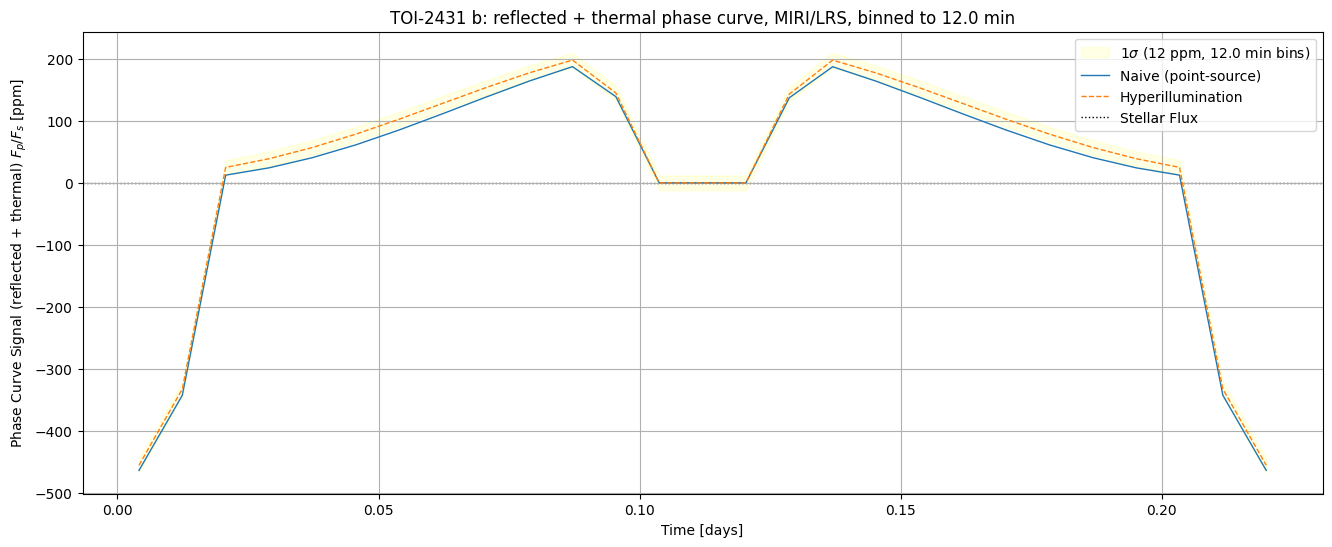

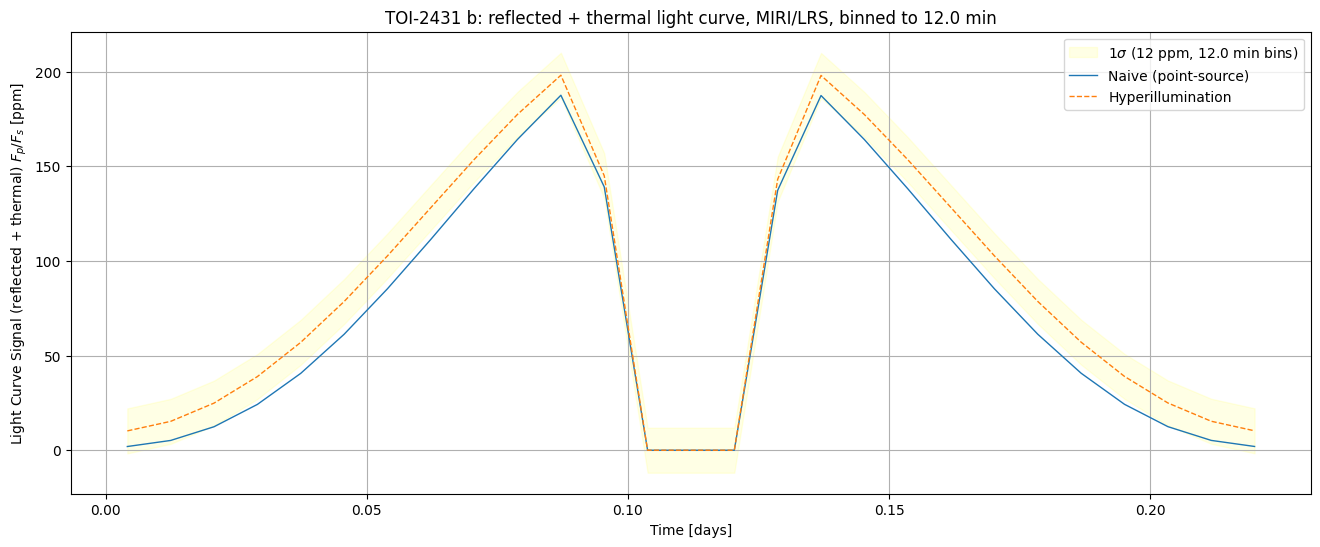

In [7]:
PAPER_MODE = False
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")
stellar_flux_line()

plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
paper_figure(f"abbias_phasecurve_binned_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
paper_figure(f"abbias_lightcurve_binned_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

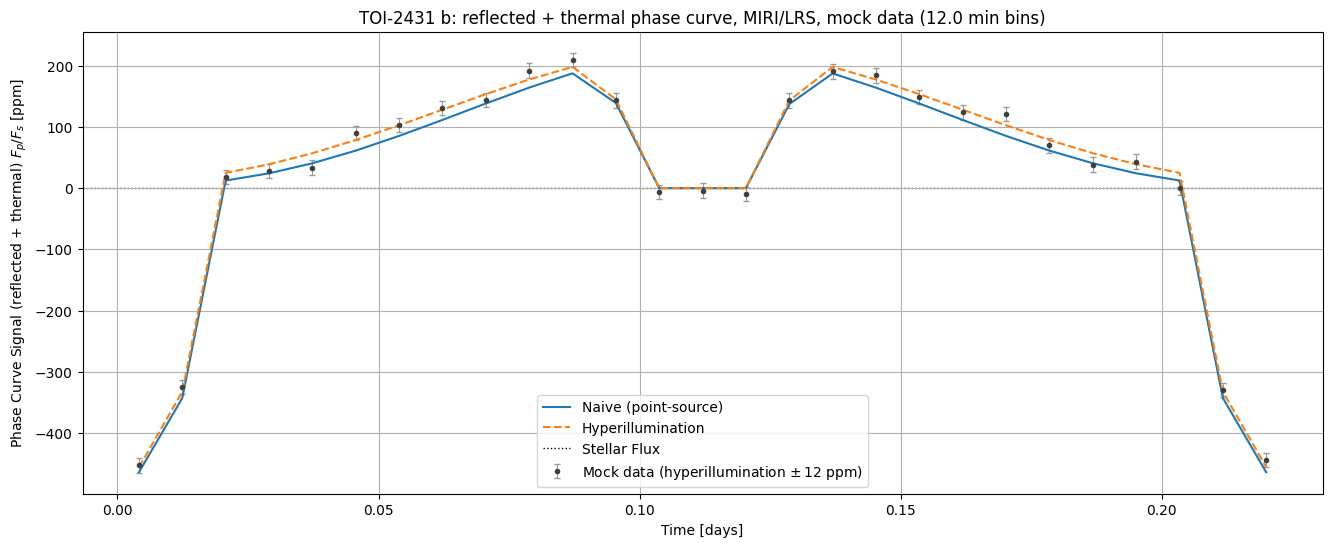

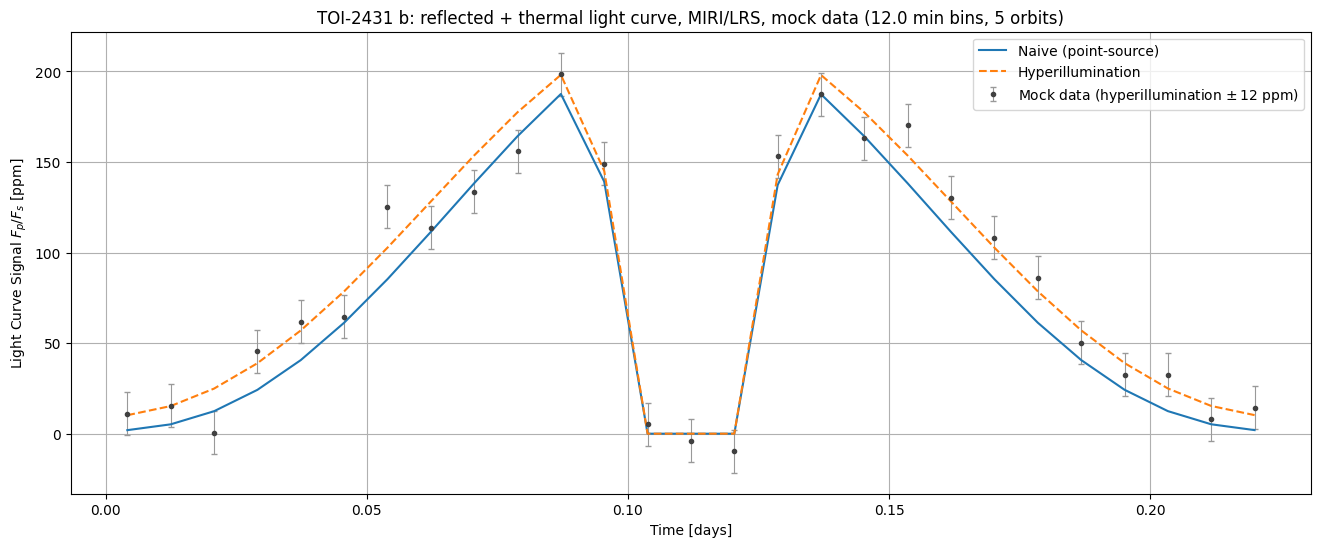

In [8]:
PAPER_MODE = False
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillum, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
stellar_flux_line()
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, mock data ({minutes_binning:.1f} min bins)")
plt.legend(); plt.grid()
paper_figure(f"abbias_phasecurve_mock_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, mock data ({minutes_binning:.1f} min bins, {n_orbits} orbits)")
plt.legend(); plt.grid()
paper_figure(f"abbias_lightcurve_mock_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected - 1-Parameter Fit

In [9]:
# demo: fit the naive model to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    print(f"A_B: {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} "
          f"({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  chi2={chi2:.3f}  "
          f"resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma "
          f"({cfg.n_orbits} orbits, {cfg.n_bins} bins)")

A_B: 0.300 -> 0.249  bias=-0.051 (-17.0%)  chi2=4.989  resid_rms=5.11 ppm  significance=2.23 sigma (5 orbits, 27 bins)
A_B: 0.300 -> 0.089  bias=-0.211 (-70.4%)  chi2=12.916  resid_rms=8.22 ppm  significance=3.59 sigma (5 orbits, 27 bins)


free offset="False" not really meaningful since normalization has error...

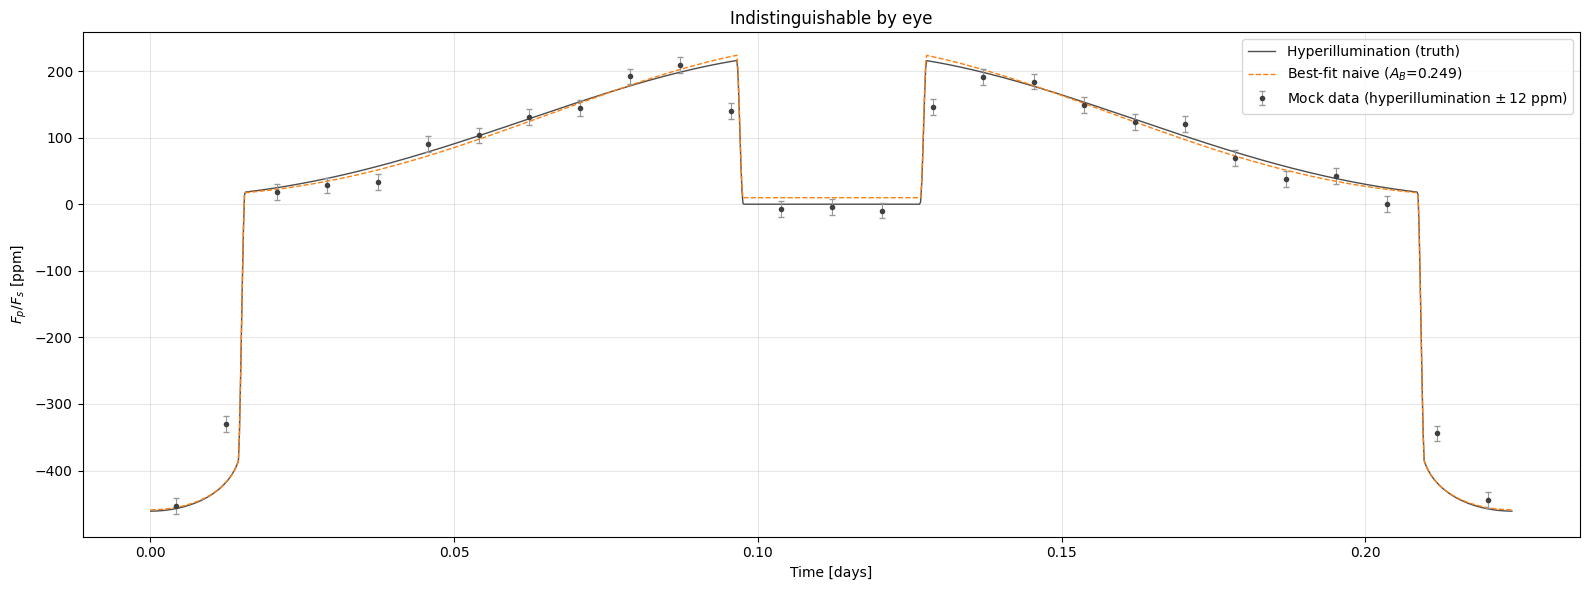

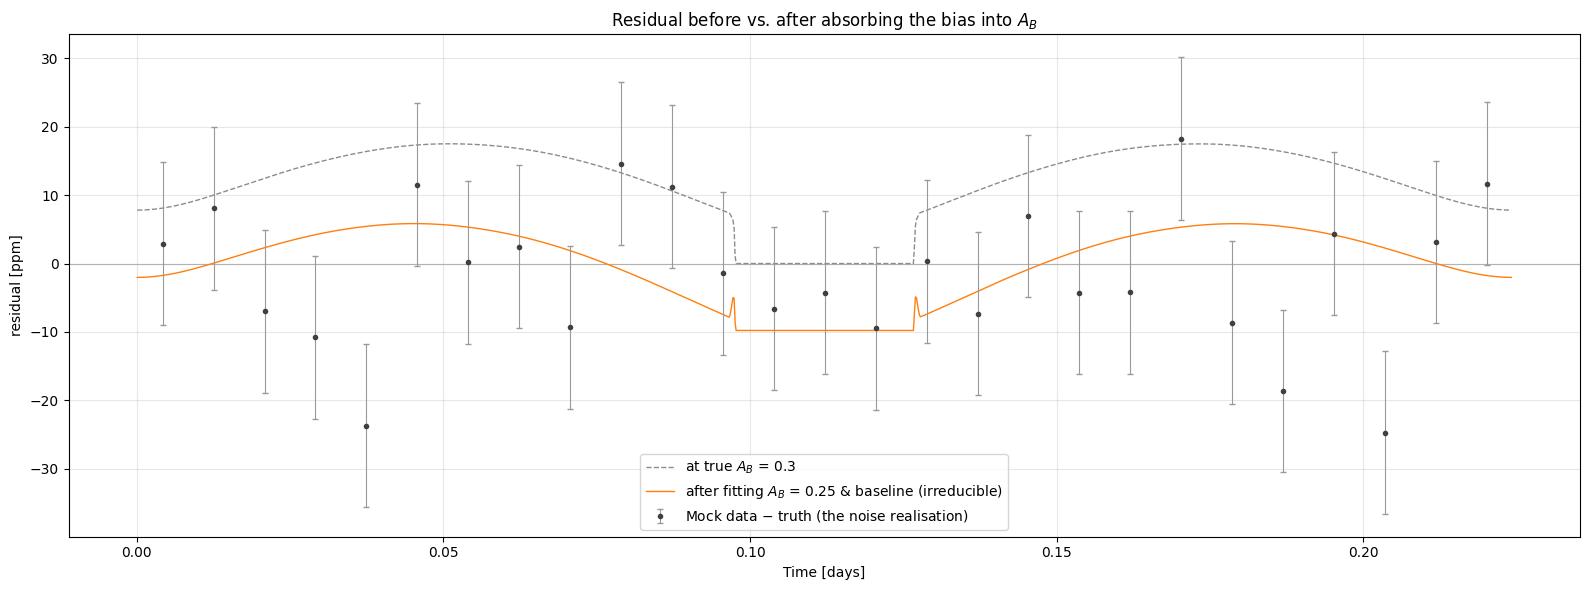

In [10]:
PAPER_MODE = False
# before vs after absorbing the bias into A_B
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(43).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.
mock_kw = dict(fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2, zorder=5)

# Figure 1: truth vs best-fit naive
fig, ax = plt.subplots(figsize=(16, 6))
ax.errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **mock_kw)
ax.plot(t_, truth,   lw=1, color="0.3", label="Hyperillumination (truth)")
ax.plot(t_, naive_f, lw=1, ls="--", color="C1", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax.set_ylabel(r"$F_p/F_s$ [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title("Indistinguishable by eye")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
paper_figure(f"abbias_fit_vs_truth_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

# Figure 2: both residuals combined on one axes, with the same mock data as the noise the bias has to beat
fig, ax = plt.subplots(figsize=(16, 6))
ax.axhline(0., color="0.7", lw=.8, zorder=1)
ax.errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **mock_kw)
ax.plot(t_, truth - naive_0, lw=1, ls="--", color="0.55", label=rf"at true $A_B$ = {A_B_true:.1f}")
ax.plot(t_, truth - naive_f, lw=1, color="C1", label=rf"after fitting $A_B$ = {A_fit:.2f} & baseline (irreducible)")
ax.set_ylabel("residual [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title(r"Residual before vs. after absorbing the bias into $A_B$")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
paper_figure(f"abbias_residuals_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

### 3. Bias vs. true Bond albedo $A_B$

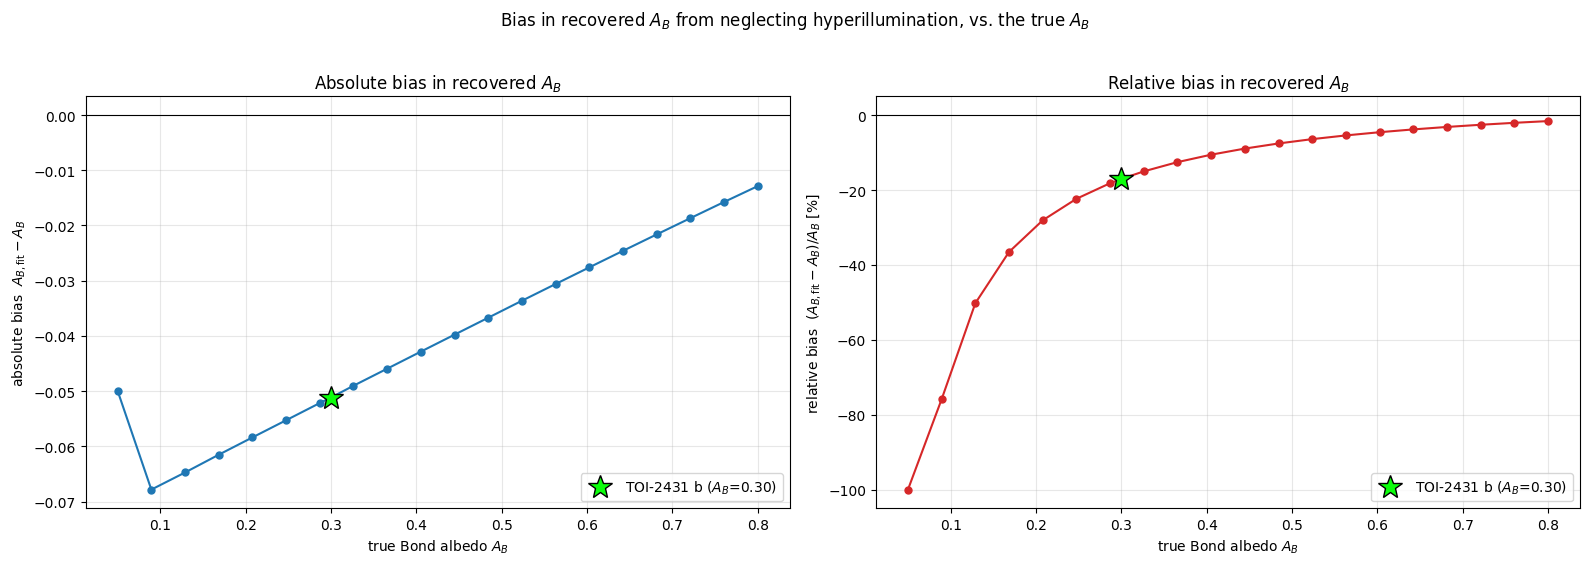

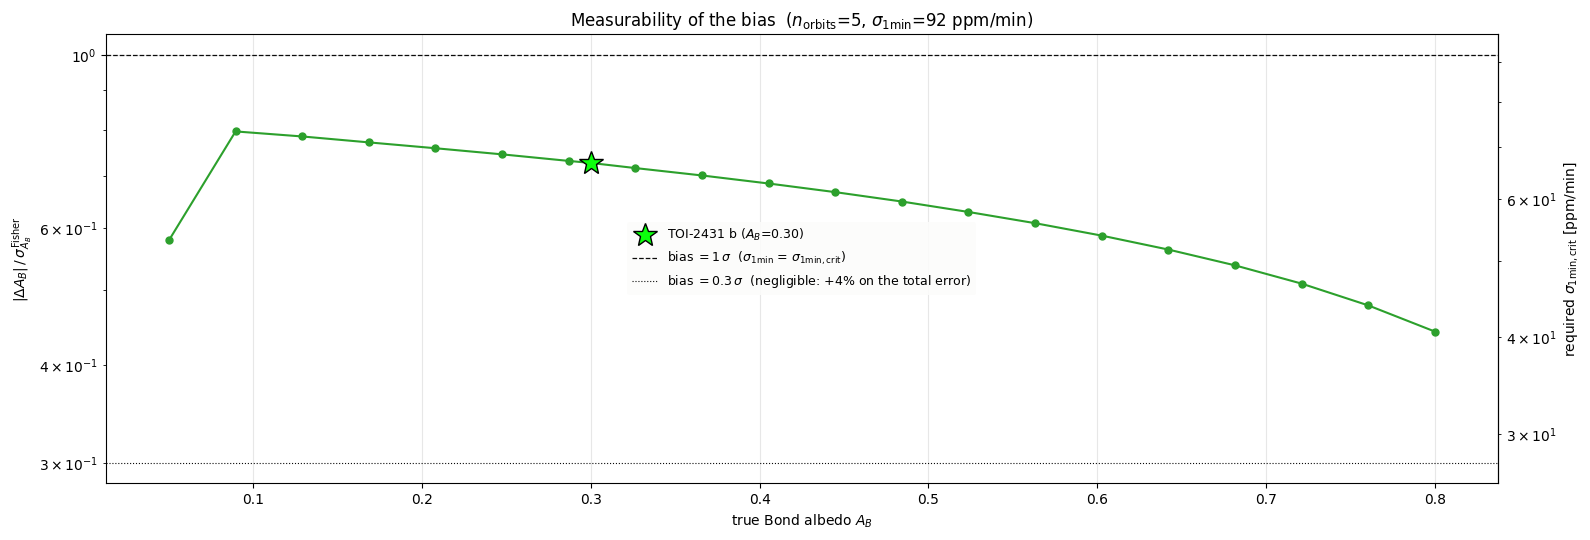

at TOI-2431 b (A_B=0.30): bias -0.0512,  sigma_A_B = 0.0704  ->  |bias|/sigma = 0.73
   sigma_1min = 91.9 ppm/min,  sigma_1min_crit = 66.8 ppm/min  ->  1.4x finer photometry, or 9 orbits instead of 5, before the bias reaches 1 sigma


In [11]:
PAPER_MODE = False
# Vary the TRUE Bond albedo and refit the naive model at each value (single target geometry,
# free baseline; free_offset=False is not meaningful here -- see 2.). Bias = A_fit - A_B_true.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))

# naive fit at each true A_B (A_fit constrained to physical [0, 1]) plus its Fisher sigma, evaluated at the FIT, where the naive posterior sits
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=False)["naive"]
bias_abs, sigma_fisher = sweep["bias_A_B"], sweep["sigma_A_B"]
bias_rel = 100. * bias_abs / A_B_grid
bias_sigma, sigma_1min_crit = measurability(bias_abs, sigma_fisher, cfg.sigma_1min)   # |bias| in units of sigma_A_B at the CURRENT sigma_1min, and the per-minute precision at which |bias| = sigma_A_B
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))   # absolute | relative
for a_, y, ylab, ttl, col in ((ax[0], bias_abs, r"absolute bias  $A_{B,\rm fit}-A_B$", "Absolute", "C0"),
                              (ax[1], bias_rel, r"relative bias  $(A_{B,\rm fit}-A_B)/A_B$ [%]", "Relative", "C3")):
    a_.axhline(0, color="k", lw=.8)
    a_.plot(A_B_grid, y, "o-", color=col, lw=1.5, ms=5)
    a_.plot(A_B_grid[i0], y[i0], "*", color="#0cff0c", ms=18, mec="k", label=f"{planet.name} ($A_B$={A_B_true:.2f})")
    a_.set_xlabel(r"true Bond albedo $A_B$"); a_.set_ylabel(ylab)
    a_.set_title(ttl + r" bias in recovered $A_B$"); a_.grid(alpha=.3); a_.legend()
fig.suptitle("Bias in recovered $A_B$ from neglecting hyperillumination, vs. the true $A_B$", y=1.02)
fig.tight_layout()
paper_figure(f"abbias_vs_true_AB_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

# Is the bias measurable? |bias| / sigma_A_B, with sigma_A_B from the inverted Fisher matrix (offset marginalised, as in the fit).
# The right axis is the SAME curve scaled by cfg.sigma_1min: the per-minute precision at which the bias would be a 1-sigma effect.
# So the dashed horizontal line is where the instrument actually sits - the curve crossing it is the point where hyperillumination stops being ignorable.
fig, a_ = plt.subplots(figsize=(16, 5.5))
measurability_panel(a_, A_B_grid, [(bias_sigma, "o-", "C2", None)], i0, cfg, f"{planet.name} ($A_B$={A_B_true:.2f})",
                    r"$|\Delta A_B|\,/\,\sigma_{A_B}^{\rm Fisher}$",
                    r"Measurability of the bias  ($n_{\rm orbits}$=%d, $\sigma_{1\rm min}$=%.0f ppm/min)" % (cfg.n_orbits, cfg.sigma_1min))
a_.grid(alpha=.3)
fig.tight_layout()
paper_figure(f"abbias_measurability_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, titles="remove")   # the secondary y-axis counts as a second axes, so the title has to be removed explicitly
plt.show()

fac = cfg.sigma_1min / sigma_1min_crit[i0]   # how much finer the photometry must get before the bias is a 1-sigma effect
print(f"at {planet.name} (A_B={A_B_true:.2f}): bias {bias_abs[i0]:+.4f},  sigma_A_B = {sigma_fisher[i0]:.4f}  ->  |bias|/sigma = {bias_sigma[i0]:.2f}")
print(f"   sigma_1min = {cfg.sigma_1min:.1f} ppm/min,  sigma_1min_crit = {sigma_1min_crit[i0]:.1f} ppm/min"
      f"  ->  {fac:.1f}x finer photometry, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits}, before the bias reaches 1 sigma")


At low true $A_B$ the best-fit naive albedo can rail at the physical floor $A_{B,\rm fit}=0$ (the naive model is driven to zero albedo); the absolute bias then saturates at $-A_B$ and the relative bias at $-100\%$. Whether and below which $A_B$ it rails depends on the configuration: it does for the lowest grid points with MIRI/LRS but not at all with NIRSpec G395H NRS1 (both TOI-2431 b, $A = 0.1$); section 3 of `F_AB_Bias.ipynb` prints the railed points. So far the bias has been negative throughout, with its magnitude shrinking as $A_B\to1$.